In [26]:
!unzip archive.zip

Archive:  archive.zip
  inflating: test_Y3wMUE5_7gLdaTN.csv  
  inflating: train_u6lujuX_CVtuZ9i.csv  


In [27]:
import pandas as pd

df_loan = pd.read_csv('train_u6lujuX_CVtuZ9i.csv')

print(f"عدد العملاء: {df_loan.shape[0]} | عدد الخصائص (الأعمدة): {df_loan.shape[1]}")
print("-" * 50)

df_loan.head(5)

عدد العملاء: 614 | عدد الخصائص (الأعمدة): 13
--------------------------------------------------


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [28]:
print("عدد القيم المفقودة في كل عمود قبل التنظيف:")
print(df_loan.isnull().sum())
print("-" * 50)

categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']
for col in categorical_cols:
    df_loan[col] = df_loan[col].fillna(df_loan[col].mode()[0])


numerical_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in numerical_cols:
    df_loan[col] = df_loan[col].fillna(df_loan[col].median())


print("عدد القيم المفقودة بعد التنظيف الأولي:")
print(df_loan.isnull().sum())

عدد القيم المفقودة في كل عمود قبل التنظيف:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64
--------------------------------------------------
عدد القيم المفقودة بعد التنظيف الأولي:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [30]:
if 'Loan_ID' in df_loan.columns:
    df_loan = df_loan.drop(columns=['Loan_ID'])

binary_cols = {'Gender': {'Male': 1, 'Female': 0},
               'Married': {'Yes': 1, 'No': 0},
               'Education': {'Graduate': 1, 'Not Graduate': 0},
               'Self_Employed': {'Yes': 1, 'No': 0},
               'Loan_Status': {'Y': 1, 'N': 0}}

for col, mapping in binary_cols.items():
    df_loan[col] = df_loan[col].map(mapping)


df_encoded = pd.get_dummies(df_loan, columns=['Dependents', 'Property_Area'], drop_first=True)

print(f" {df_encoded.shape}")
print("-" * 50)

df_encoded.head(5)

 (614, 15)
--------------------------------------------------


,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Dependents_1,Dependents_2,Dependents_3+,Property_Area_Semiurban,Property_Area_Urban
0,1,0,1,0,5849,0.0,128.0,360.0,1.0,1,False,False,False,False,True
1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0,True,False,False,False,False
2,1,1,1,1,3000,0.0,66.0,360.0,1.0,1,False,False,False,False,True
3,1,1,0,0,2583,2358.0,120.0,360.0,1.0,1,False,False,False,False,True
4,1,0,1,0,6000,0.0,141.0,360.0,1.0,1,False,False,False,False,True


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. تحديد الميزات (X) والمتغير المستهدف (y)
X = df_encoded.drop(columns=['Loan_Status'])
y = df_encoded['Loan_Status']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"حجم بيانات التدريب: {X_train.shape[0]} عميل")
print(f"حجم بيانات الاختبار: {X_test.shape[0]} عميل")
print("-" * 50)

lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
lr_acc = accuracy_score(y_test, lr_preds)

print(f"🎯 دقة نموذج Logistic Regression هي: {lr_acc:.2%}")


rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)

print(f"🎯 دقة نموذج Random Forest هي: {rf_acc:.2%}")

حجم بيانات التدريب: 491 عميل
حجم بيانات الاختبار: 123 عميل
--------------------------------------------------


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


🎯 دقة نموذج Logistic Regression هي: 78.86%
🎯 دقة نموذج Random Forest هي: 77.24%


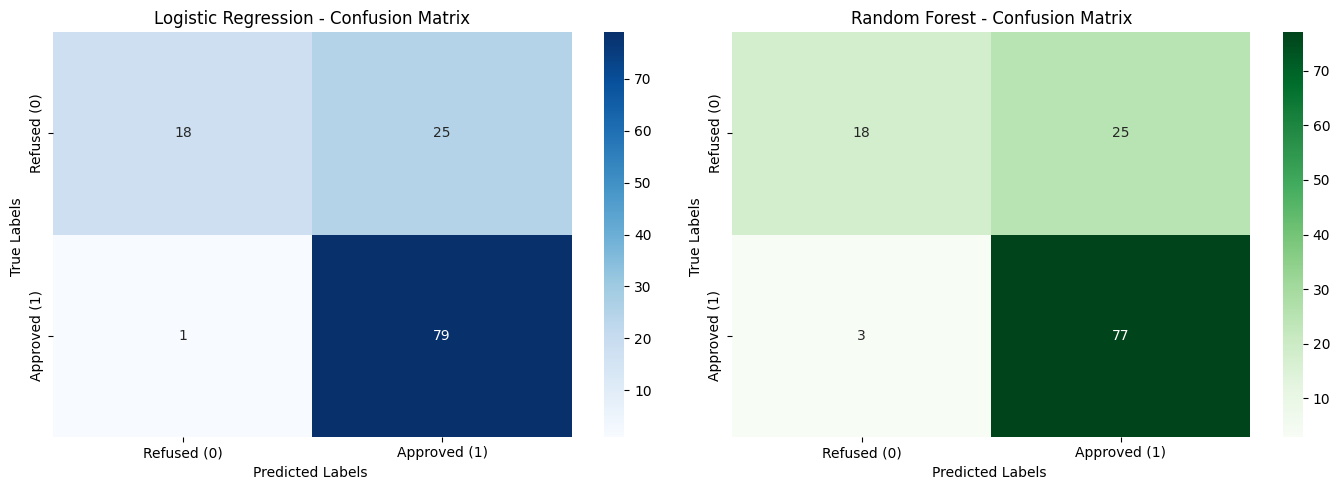

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


cm_lr = confusion_matrix(y_test, lr_preds)
cm_rf = confusion_matrix(y_test, rf_preds)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Refused (0)', 'Approved (1)'],
            yticklabels=['Refused (0)', 'Approved (1)'])
axes[0].set_title('Logistic Regression - Confusion Matrix')
axes[0].set_xlabel('Predicted Labels ')
axes[0].set_ylabel('True Labels ')


sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Refused (0)', 'Approved (1)'],
            yticklabels=['Refused (0)', 'Approved (1)'])
axes[1].set_title('Random Forest - Confusion Matrix')
axes[1].set_xlabel('Predicted Labels ')
axes[1].set_ylabel('True Labels ')

plt.tight_layout()
plt.show()